# AutoInsight — Vehicle Damage Segmentation (Kaggle GPU)

**Goal:** train a segmentation model to locate vehicle damage regions such as dents, scratches and cracks using CarDD annotations.

**Model:** YOLO26m-seg (medium segmentation model; higher capacity than the original YOLO26s-seg). The setup falls back to YOLO11m-seg if needed. This is a strong accuracy-oriented baseline, not a guarantee of maximum accuracy.

This notebook keeps polygon annotations when converting COCO to YOLO segmentation labels. RLE or empty polygon annotations are approximated using bounding-box polygons, which are less precise. Review the conversion statistics and mask overlays before training.

Kaggle migration: no Google Drive mount; input dataset is read from `/kaggle/input`; generated dataset, checkpoints and exports are written to `/kaggle/working`.


In [2]:
%pip install -q -U ultralytics opencv-python-headless pyyaml

import os, json, time, shutil, random
from pathlib import Path
from collections import Counter
import yaml, cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
assert torch.cuda.is_available(), "Enable a GPU accelerator in Kaggle Notebook Settings."


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 MB 17.2 MB/s eta 0:00:0000:0100:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 4.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.184
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [3]:
# Kaggle does not use Google Drive mounting.
print("Kaggle input root exists:", os.path.isdir("/kaggle/input"))


Kaggle input root exists: True


## Config

In [15]:
# ============================================================
# AutoInsight — CarDD Vehicle Damage Segmentation Configuration
# Kaggle GPU Environment
# ============================================================

import os
import time
from pathlib import Path

# ------------------------------------------------------------
# 1. Automatically locate the CarDD COCO dataset
# ------------------------------------------------------------

def find_cardd_roots(input_root="/kaggle/input"):
    found = []

    for root, dirs, files in os.walk(input_root):
        if (
            os.path.isdir(os.path.join(root, "annotations"))
            and os.path.isdir(os.path.join(root, "train2017"))
            and os.path.isdir(os.path.join(root, "val2017"))
            and os.path.isdir(os.path.join(root, "test2017"))
            and os.path.isfile(
                os.path.join(
                    root,
                    "annotations",
                    "instances_train2017.json"
                )
            )
        ):
            found.append(root)

    return sorted(set(found))


CARDD_CANDIDATES = find_cardd_roots()

print("Detected CarDD dataset candidates:")

for path in CARDD_CANDIDATES:
    print(" -", path)

if not CARDD_CANDIDATES:
    print("\nAvailable Kaggle input directories:")

    for path in Path("/kaggle/input").iterdir():
        print(" -", path)

    raise FileNotFoundError(
        "CarDD COCO dataset was not found. "
        "Check the dataset folder structure and annotation filename."
    )

# Automatically select the dataset if exactly one valid root exists.
if len(CARDD_CANDIDATES) == 1:
    COCO_DRIVE_DIR = CARDD_CANDIDATES[0]
else:
    preferred = [
        path for path in CARDD_CANDIDATES
        if "cardd_coco" in path.lower()
    ]

    if len(preferred) == 1:
        COCO_DRIVE_DIR = preferred[0]
    else:
        raise RuntimeError(
            "Multiple CarDD dataset roots were detected. "
            "Set COCO_DRIVE_DIR manually to the correct dataset root:\n"
            + "\n".join(CARDD_CANDIDATES)
        )

print("\nSelected CarDD dataset:", COCO_DRIVE_DIR)

# ------------------------------------------------------------
# 2. Verify dataset directories and annotations
# ------------------------------------------------------------

for folder in ["annotations", "train2017", "val2017", "test2017"]:
    path = os.path.join(COCO_DRIVE_DIR, folder)

    assert os.path.isdir(path), (
        f"Required dataset directory is missing: {path}"
    )

annotation_file = os.path.join(
    COCO_DRIVE_DIR,
    "annotations",
    "instances_train2017.json"
)

assert os.path.isfile(annotation_file), (
    f"Training annotation file not found: {annotation_file}"
)

print("Dataset directory checks passed.")

# ------------------------------------------------------------
# 3. Training configuration
# ------------------------------------------------------------

OUT_DRIVE_DIR = "/kaggle/working/autoinsight_models/damage"

# Optional: path to a previously trained checkpoint.
OLD_WEIGHTS = None

# Use YOLO11 segmentation as the default checkpoint.
MODEL = "yolo11m-seg.pt"

IMGSZ = 960
EPOCHS = 50
TIME_H = 8.0
BATCH = 4

RUN_NAME = time.strftime(
    "damage_seg_kaggle_%Y%m%d_%H%M"
)

PROMOTE = False

# ------------------------------------------------------------
# 4. Local dataset conversion paths
# ------------------------------------------------------------

LOCAL_COCO = "/kaggle/working/CarDD_COCO"
LOCAL_YOLO = "/kaggle/working/CARDD_YOLO_SEG"

YAML_PATH = os.path.join(LOCAL_YOLO, "data.yaml")

os.makedirs(OUT_DRIVE_DIR, exist_ok=True)

# ------------------------------------------------------------
# 5. Display configuration
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("AUTOINSIGHT SEGMENTATION CONFIGURATION")
print("=" * 55)

print("Dataset root :", COCO_DRIVE_DIR)
print("Annotations  :", annotation_file)
print("Output       :", OUT_DRIVE_DIR)
print("Model        :", MODEL)
print("Image size   :", IMGSZ)
print("Epochs       :", EPOCHS)
print("Batch size   :", BATCH)
print("Time limit   :", TIME_H, "hours")
print("Run name     :", RUN_NAME)
print("YOLO dataset :", YAML_PATH)

print("\nConfiguration completed successfully.")

Detected CarDD dataset candidates:
 - /kaggle/input/datasets/pesreward/cardamage/CarDD_COCO

Selected CarDD dataset: /kaggle/input/datasets/pesreward/cardamage/CarDD_COCO
Dataset directory checks passed.

AUTOINSIGHT SEGMENTATION CONFIGURATION
Dataset root : /kaggle/input/datasets/pesreward/cardamage/CarDD_COCO
Annotations  : /kaggle/input/datasets/pesreward/cardamage/CarDD_COCO/annotations/instances_train2017.json
Output       : /kaggle/working/autoinsight_models/damage
Model        : yolo11m-seg.pt
Image size   : 960
Epochs       : 50
Batch size   : 4
Time limit   : 8.0 hours
Run name     : damage_seg_kaggle_20261023_1902
YOLO dataset : /kaggle/working/CARDD_YOLO_SEG/data.yaml

Configuration completed successfully.


## 1. Copy the raw dataset to local disk and verify it
Converting straight on Drive took ~40 minutes before; local disk takes a couple of minutes.

In [8]:
# Copy attached read-only Kaggle input to writable local scratch for conversion.
if os.path.isdir(LOCAL_COCO):
    shutil.rmtree(LOCAL_COCO)
t = time.time()
shutil.copytree(COCO_DRIVE_DIR, LOCAL_COCO)
print(f"Copied CarDD in {time.time()-t:.1f}s")

EXPECTED = {"train2017": 2816, "val2017": 810, "test2017": 374}
for split, n in EXPECTED.items():
    have = len([f for f in os.listdir(f"{LOCAL_COCO}/{split}")
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))])
    print(f"{split}: {have} images (expected {n})")
    assert have == n, (
        f"{split} count differs from the expected official split. "
        "Verify this is the intended CarDD version before continuing."
    )


Copied CarDD in 756.2s
train2017: 2816 images (expected 2816)
val2017: 810 images (expected 810)
test2017: 374 images (expected 374)


## 2. Convert COCO -> YOLO segmentation labels (tested code - polygons are kept)

In [9]:
# ---- COCO (CarDD) -> YOLO segmentation labels -------------------------------------------
import json, os, shutil
from collections import Counter

def coco_to_yolo_seg(json_path, image_dir, out_images, out_labels, class_ids):
    """
    Writes one YOLO-seg label file per image (polygons, not just boxes) and copies the image.
    Returns a Counter with what happened, so nothing is dropped silently.
    """
    with open(json_path) as f:
        coco = json.load(f)
    images = {im['id']: im for im in coco['images']}
    by_image = {}
    for ann in coco['annotations']:
        by_image.setdefault(ann['image_id'], []).append(ann)

    os.makedirs(out_images, exist_ok=True)
    os.makedirs(out_labels, exist_ok=True)
    stats = Counter()
    per_class = Counter()

    for image_id, im in images.items():
        W, H = im['width'], im['height']
        src = os.path.join(image_dir, im['file_name'])
        if not os.path.exists(src):
            stats['missing_image'] += 1
            continue
        shutil.copy2(src, os.path.join(out_images, im['file_name']))

        lines = []
        for ann in by_image.get(image_id, []):
            if ann['category_id'] not in class_ids:
                stats['unknown_class'] += 1
                continue
            cls = class_ids[ann['category_id']]
            seg = ann.get('segmentation')
            polys = [p for p in seg if len(p) >= 6] if isinstance(seg, list) else []
            if not polys:   # RLE / empty polygon: keep the instance as its box instead of losing it
                x, y, w, h = ann['bbox']
                polys = [[x, y, x + w, y, x + w, y + h, x, y + h]]
                stats['bbox_fallback'] += 1
            if len(polys) > 1:
                stats['annotations_with_several_polygons'] += 1
            for poly in polys:       # each polygon becomes its own instance
                pts = []
                for k in range(0, len(poly) - 1, 2):
                    pts += [min(max(poly[k] / W, 0.0), 1.0), min(max(poly[k + 1] / H, 0.0), 1.0)]
                lines.append(f"{cls} " + " ".join(f"{v:.6f}" for v in pts))
                stats['instances'] += 1
                per_class[cls] += 1

        with open(os.path.join(out_labels, os.path.splitext(im['file_name'])[0] + '.txt'), 'w') as f:
            f.write("\n".join(lines))
        stats['images'] += 1
    stats['_per_class'] = dict(per_class)
    return stats


def check_yolo_split(root, split):
    """Hard consistency check - a label for every image and an image for every label."""
    imgs = {os.path.splitext(f)[0] for f in os.listdir(f'{root}/images/{split}')}
    labs = {os.path.splitext(f)[0] for f in os.listdir(f'{root}/labels/{split}') if f.endswith('.txt')}
    problems = {'images_without_label': sorted(imgs - labs)[:5], 'labels_without_image': sorted(labs - imgs)[:5]}
    ok = imgs == labs
    print(f"{split:5} images={len(imgs):5} labels={len(labs):5}  {'OK' if ok else 'MISMATCH ' + str(problems)}")
    return ok

In [10]:
with open(f'{LOCAL_COCO}/annotations/instances_train2017.json') as f:
    cats = sorted(json.load(f)['categories'], key=lambda c: c['id'])
class_ids   = {c['id']: i for i, c in enumerate(cats)}
class_names = [c['name'] for c in cats]
print(class_names)

shutil.rmtree(LOCAL_YOLO, ignore_errors=True)        # local scratch copy only - Drive is never touched here
for split, coco_split in {'train': 'train2017', 'val': 'val2017', 'test': 'test2017'}.items():
    st = coco_to_yolo_seg(f'{LOCAL_COCO}/annotations/instances_{coco_split}.json', f'{LOCAL_COCO}/{coco_split}',
                          f'{LOCAL_YOLO}/images/{split}', f'{LOCAL_YOLO}/labels/{split}', class_ids)
    per = {class_names[k]: v for k, v in sorted(st.pop('_per_class').items())}
    print(split, dict(st)); print('   instances per class:', per)

assert all(check_yolo_split(LOCAL_YOLO, s) for s in ('train', 'val', 'test')), 'dataset is inconsistent - fix before training'
with open(YAML_PATH, 'w') as f:
    yaml.safe_dump({'path': LOCAL_YOLO, 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'names': class_names}, f, sort_keys=False)
print(open(YAML_PATH).read())

['dent', 'scratch', 'crack', 'glass shatter', 'lamp broken', 'tire flat']
train {'instances': 6211, 'images': 2816}
   instances per class: {'dent': 1806, 'scratch': 2560, 'crack': 651, 'glass shatter': 475, 'lamp broken': 494, 'tire flat': 225}
val {'instances': 1744, 'images': 810}
   instances per class: {'dent': 501, 'scratch': 728, 'crack': 177, 'glass shatter': 135, 'lamp broken': 141, 'tire flat': 62}
test {'instances': 785, 'images': 374}
   instances per class: {'dent': 236, 'scratch': 307, 'crack': 70, 'glass shatter': 71, 'lamp broken': 69, 'tire flat': 32}
train images= 2816 labels= 2816  OK
val   images=  810 labels=  810  OK
test  images=  374 labels=  374  OK
path: /kaggle/working/CARDD_YOLO_SEG
train: images/train
val: images/val
test: images/test
names:
- dent
- scratch
- crack
- glass shatter
- lamp broken
- tire flat



### Sanity check: do the polygons sit on the damage?

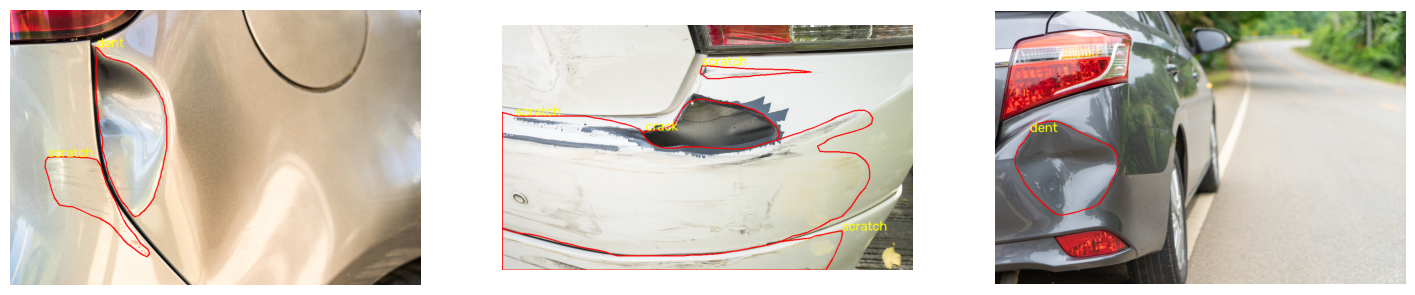

In [11]:
import numpy as np
files = random.sample(os.listdir(f'{LOCAL_YOLO}/images/train'), 3)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, files):
    img = cv2.cvtColor(cv2.imread(f'{LOCAL_YOLO}/images/train/{name}'), cv2.COLOR_BGR2RGB); h, w = img.shape[:2]
    for line in open(f"{LOCAL_YOLO}/labels/train/{os.path.splitext(name)[0]}.txt").read().splitlines():
        v = line.split(); pts = (np.array(v[1:], float).reshape(-1, 2) * [w, h]).astype(np.int32)
        cv2.polylines(img, [pts], True, (255, 0, 0), max(2, w // 400)); cv2.putText(img, class_names[int(v[0])], tuple(pts[0]), 0, w / 900, (255, 255, 0), max(1, w // 600))
    ax.imshow(img); ax.axis('off')
plt.show()

## 3. Which weights are on Drive right now?
Your two old notebooks wrote to the same folder. Evaluating the existing `best.pt` on the **complete** validation set tells you which one survived: roughly **0.71 mAP50** = the good run, **~0.49** = the run on the broken dataset.

In [12]:
def evaluate(weights, yaml_path, split='val', imgsz=640, conf=None):
    """Box (and mask, for -seg models) metrics, overall and per class."""
    m = YOLO(weights)
    kw = dict(data=yaml_path, split=split, imgsz=imgsz, plots=False, verbose=False)
    if conf is not None:
        kw['conf'] = conf                       # conf=0.35 = the operating point the server uses
    r = m.val(**kw)
    out = {'weights': weights, 'split': split, 'conf': conf, 'imgsz': imgsz,
           'box_mAP50': float(r.box.map50), 'box_mAP50_95': float(r.box.map),
           'precision': float(r.box.mp), 'recall': float(r.box.mr), 'per_class': {}}
    seg = getattr(r, 'seg', None)
    if seg is not None and hasattr(seg, 'map'):
        out['mask_mAP50'] = float(seg.map50)
        out['mask_mAP50_95'] = float(seg.map)
    for j, c in enumerate(r.box.ap_class_index):
        p, rec, ap50, ap = r.box.class_result(j)
        out['per_class'][m.names[int(c)]] = {'P': round(float(p), 3), 'R': round(float(rec), 3),
                                              'mAP50': round(float(ap50), 3), 'mAP50-95': round(float(ap), 3)}
    return out


def show(res, title=''):
    print(f"\n== {title} [{res['split']}, conf={res['conf']}, imgsz={res['imgsz']}]")
    keys = ['box_mAP50', 'box_mAP50_95', 'mask_mAP50', 'mask_mAP50_95', 'precision', 'recall']
    print('   ' + '  '.join(f"{k}={res[k]:.3f}" for k in keys if k in res))
    print(f"   {'class':16} {'P':>6} {'R':>6} {'mAP50':>7} {'mAP50-95':>9}")
    for name, v in res['per_class'].items():
        print(f"   {name:16} {v['P']:>6} {v['R']:>6} {v['mAP50']:>7} {v['mAP50-95']:>9}")

In [13]:
if OLD_WEIGHTS and os.path.isfile(OLD_WEIGHTS):
    old_val = evaluate(OLD_WEIGHTS, YAML_PATH, "val", imgsz=IMGSZ)
    show(old_val, "OLD weights — validation")
    old_test = evaluate(OLD_WEIGHTS, YAML_PATH, "test", imgsz=IMGSZ)
    show(old_test, "OLD weights — test")
else:
    old_val = old_test = None
    print("No previous checkpoint supplied; skipping old-model comparison.")


No previous checkpoint supplied; skipping old-model comparison.


## 4. Train

In [16]:
# Try the medium model first for higher capacity. Fall back only if the checkpoint cannot load.
model = None
load_errors = []
for candidate in MODEL_CANDIDATES:
    try:
        model = YOLO(candidate)
        MODEL = candidate
        print("Using pretrained segmentation model:", MODEL)
        break
    except Exception as e:
        load_errors.append(f"{candidate}: {e}")
if model is None:
    raise RuntimeError("Could not load any segmentation checkpoint:\n" + "\n".join(load_errors))

results = model.train(
    data=YAML_PATH,
    imgsz=IMGSZ,
    epochs=EPOCHS,
    time=TIME_H,
    patience=45,
    batch=BATCH,
    device=[0,1],
    cos_lr=True,
    close_mosaic=15,
    copy_paste=0.1,
    cache=False,
    workers=4,
    seed=42,
    deterministic=True,
    project=f"{OUT_DRIVE_DIR}/runs",
    name=RUN_NAME,
    exist_ok=False,
    plots=True,
)


Using pretrained segmentation model: yolo26m-seg.pt
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/CARDD_YOLO_SEG/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mix

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   seg_loss   cls_loss    l1_loss   sem_loss  Instances       Size
      2/128      4.56G       1.71      2.917      2.896    0.02392      3.031         16        960: 100% ━━━━━━━━━━━━ 704/704 3.8it/s 3:060.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 102/102 6.5it/s 15.6s0.2s
                   all        810       1744      0.417      0.489      0.408      0.198       0.44      0.494      0.413      0.246

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss    l1_loss   sem_loss  Instances       Size
      3/135      4.56G       1.72      2.872      2.721    0.02347      2.421         16        960: 100% ━━━━━━━━━━━━ 704/704 3.8it/s 3:050.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 102/102 6.8it/s 15.1s0.1s
                   

## Resume after an interruption

Kaggle may clear `/kaggle/working` when a session ends. Persist/download the run folder before stopping. If the run directory still exists, after rerunning setup and data preparation:

```python
last_path = f"{OUT_DRIVE_DIR}/runs/{RUN_NAME}/weights/last.pt"
model = YOLO(last_path)
results = model.train(resume=True)
```

If the session was reset, restore the run directory from a saved Kaggle Dataset or upload the checkpoint as notebook input.


## 5. Evaluate on validation AND test, at the server's operating threshold

In [17]:
RUN_DIR = f"{OUT_DRIVE_DIR}/runs/{RUN_NAME}"
NEW_BEST = f"{RUN_DIR}/weights/best.pt"
assert os.path.isfile(NEW_BEST), f"Best checkpoint not found: {NEW_BEST}"

new = {
    "val": evaluate(NEW_BEST, YAML_PATH, "val", imgsz=IMGSZ),
    "test": evaluate(NEW_BEST, YAML_PATH, "test", imgsz=IMGSZ),
    "test_conf0.35": evaluate(NEW_BEST, YAML_PATH, "test", imgsz=IMGSZ, conf=0.35),
}
show(new["val"], "NEW — validation")
show(new["test"], "NEW — final held-out test")
show(new["test_conf0.35"], "NEW — test at confidence 0.35 (operating-point check)")


Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26m-seg summary (fused): 146 layers, 23,512,094 parameters, 0 gradients, 121.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4305.0±1245.9 MB/s, size: 710.5 KB)
val: Scanning /kaggle/working/CARDD_YOLO_SEG/labels/val.cache... 810 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 810/810 242.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 1.0s/it 51.4s1.0ss
                   all        810       1744      0.831      0.726      0.789      0.614      0.838       0.73      0.783      0.599
Speed: 1.3ms preprocess, 58.1ms inference, 0.0ms loss, 1.3ms postprocess per image
Ultralytics 8.4.184 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26m-seg summary (fused): 146 layers, 23,512,094 parameters, 0 gradients, 121.4 GFLOPs
val: Fast image access ✅ (pi

In [18]:
if old_test:
    print("Old/new comparison (ensure the same split and comparable label definitions):")
    for k in ("box_mAP50", "box_mAP50_95", "mask_mAP50", "mask_mAP50_95"):
        if k in old_test and k in new["test"]:
            print(f"{k}: old={old_test[k]:.3f}, new={new['test'][k]:.3f}")


## 6. Save a model card, and (optionally) promote to what the server loads

In [19]:
card = {
    "run": RUN_NAME,
    "date": time.strftime("%Y-%m-%d %H:%M"),
    "base_model": MODEL,
    "imgsz": IMGSZ,
    "epochs_planned": EPOCHS,
    "time_cap_h": TIME_H,
    "ultralytics": ultralytics.__version__,
    "classes": class_names,
    "task": "segment",
    "dataset": {s: len(os.listdir(f"{LOCAL_YOLO}/images/{s}")) for s in ("train", "val", "test")},
    "metrics": new,
    "old_weights_metrics_test": old_test,
}
with open(f"{RUN_DIR}/model_card.json", "w") as f:
    json.dump(card, f, indent=2)

EXPORT_DIR = "/kaggle/working/damage_model_export"
os.makedirs(EXPORT_DIR, exist_ok=True)
shutil.copy2(NEW_BEST, f"{EXPORT_DIR}/best.pt")
with open(f"{EXPORT_DIR}/classes.json", "w") as f:
    json.dump(class_names, f, indent=2)
shutil.copy2(f"{RUN_DIR}/model_card.json", f"{EXPORT_DIR}/model_card.json")
shutil.make_archive("/kaggle/working/damage_model_export", "zip", EXPORT_DIR)
print("Export created: /kaggle/working/damage_model_export.zip")

if PROMOTE:
    target = f"{OUT_DRIVE_DIR}/best.pt"
    if os.path.exists(target):
        backup = f"{OUT_DRIVE_DIR}/best_prev_{time.strftime('%Y%m%d_%H%M')}.pt"
        shutil.copy2(target, backup)
        print("Backed up previous checkpoint:", backup)
    shutil.copy2(NEW_BEST, target)
    print("Promoted:", target)
else:
    print("Not promoted. Review metrics and predictions before changing PROMOTE=True.")
print("Backend target after approval: backend/models/damage/best.pt")


Export created: /kaggle/working/damage_model_export.zip
Not promoted. Review metrics and predictions before changing PROMOTE=True.
Backend target after approval: backend/models/damage/best.pt


## After this notebook
* The backend currently ignores masks and uses boxes only. To benefit from the segmentation model, `damage_detector.py` and `fusion_service.py` need a small change so the **damage mask** (not its box) is intersected with the part mask - ask for it once these weights are trained.
* Look at the `dent / scratch / crack` rows in the test table. If recall at conf 0.35 is still low, the next gain is **more data** (your own labelled service-centre photos), not more epochs.

## Accuracy checklist before accepting this model

1. Verify the mask overlays before training; annotation conversion errors cap model accuracy.
2. Review mask mAP and per-class precision/recall for each damage category.
3. Use validation data to tune confidence threshold and image size; do not tune on test results.
4. Run inference on independent real vehicle photos, including close-ups, varied lighting and different paint colours.
5. If CUDA OOM occurs, reduce `BATCH` from 4 to 2 before reducing image size. A lower image size can hurt thin scratch/crack localization.
6. The current AutoInsight backend must consume predicted masks to benefit from segmentation. Update the detector/fusion service after exporting these weights.
7. For real-world accuracy, add representative service-centre images with carefully reviewed polygon labels; benchmark on a held-out real-world set.


In [20]:
import os

paths = [
    "/kaggle/working/yolo26m-seg.pt",
]

for root, dirs, files in os.walk("/kaggle/working"):
    for filename in files:
        if filename in ["best.pt", "last.pt", "yolo26m-seg.pt"]:
            paths.append(os.path.join(root, filename))

for path in sorted(set(paths)):
    if os.path.isfile(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"{path}: {size_mb:.2f} MB")

/kaggle/working/autoinsight_models/damage/runs/damage_seg_kaggle_20261023_1902/weights/best.pt: 52.01 MB
/kaggle/working/autoinsight_models/damage/runs/damage_seg_kaggle_20261023_1902/weights/last.pt: 52.01 MB
/kaggle/working/damage_model_export/best.pt: 52.01 MB
/kaggle/working/yolo26m-seg.pt: 52.21 MB
